# ¿Generaliza mejor DINOv2 que una CNN supervisada al detectar deepfakes?

**Ejecución de la intervención preliminar definida en E1.pdf**

INF659 · Deep Learning · Maestría en Informática · 2026-2
Integrantes: Christian Carhuancho, Jorge Chamorro, Jorge Fatama
Docentes: Dr. César A. Beltrán Castañón, Dr. Rodrigo Uribe
12 de octubre de 2026

Este cuaderno ejecuta esa intervención preliminar sobre `dfdc_train_part_0`, que es el fragmento elegido en el informe.

La comparación de este cuaderno es la de la Tabla 4 del informe:

| Modelo | Protocolo |
| --- | --- |
| A | EfficientNet-B0, ImageNet, fine-tuning completo, cinco épocas |
| B | DINOv2 ViT-S/14 congelado; el token CLS entra a una regresión logística |

Lo que el informe deja para después (LoRA, fine-tuning parcial, Self-Blended Images, FaceForensics++ y Celeb-DF) no se ejecuta aquí.


## 1. Propuesta

La pregunta principal del informe es si el preentrenamiento auto-supervisado de DINOv2 mejora la generalización entre métodos de manipulación y entre datasets frente a EfficientNet-B0, y qué estrategia de adaptación conviene. Las preguntas secundarias preguntan en qué capas de DINOv2 está la señal (PS1), cuánto ayudan esas características cuando hay pocas etiquetas (PS2) y cómo pegan la compresión, la resolución y el cambio de método (PS3).

Las hipótesis de todo el estudio, copiadas del informe con su matiz bibliográfico, son estas:

| ID | Hipótesis | Qué dice la literatura citada en el informe |
| --- | --- | --- |
| H-A | B0 rendirá mejor dentro de DFDC, porque el fine-tuning ve los artefactos de ese conjunto. | Nguyen, Yamagishi y Echizen (2024) vieron que ViT auto-supervisados grandes superaban a EfficientNetV2-Large incluso en datos vistos. Aquí el par es más chico: B0 contra ViT-S/14, con cinco épocas. |
| H-B | DINOv2 perderá menos AUC al cambiar de dataset. | El mismo trabajo ve mejor generalización del fine-tuning parcial de DINOv2 que de MAE, y aun así todos empeoran fuera de distribución. Su métrica es EER sobre imágenes, no vídeos de DFDC. |
| H-C | Las capas intermedias de DINOv2 serán más útiles que la última para la huella de falsificación. | Nguyen et al. (2024) dicen que varios bloques finales superan al último solo. No comparan el medio de la red contra el final: ese es el hueco que PS1 quiere medir. |
| H-D | Self-Blended Images mejorará la generalización más que cambiar el backbone. | Shiohara y Yamasaki (2022). No se ejecuta en este cuaderno. |

Este cuaderno solo puede hablar de las tres hipótesis preliminares del informe (Tabla 5), medidas dentro de `dfdc_train_part_0` y con degradaciones sintéticas. H-B y H-D quedan abiertas: FaceForensics++ y Celeb-DF siguen pendientes de acceso, como dice el propio informe.


## 2. Related work inicial

La revisión sigue las cuatro líneas del informe.

**Datasets.** Dolhansky et al. (2020) publican DFDC. La página de la competencia (Kaggle, 2020) precisa el formato: vídeos `.mp4`, un `metadata.json` con `label`, `original` y `split`, y la posibilidad de que un falso sea de cara, de voz o de ambas. FaceForensics++ (Rössler et al., 2019) y Celeb-DF v2 (Li et al., 2020) son los bancos previstos para salir de DFDC. DeepfakeBench (Yan et al., 2023) unifica procesamiento, métricas y protocolos sobre 15 detectores y 9 conjuntos. Esos dos conjuntos externos no están en esta corrida.

**Frames promediados.** El informe adopta clasificar cada frame y promediar la probabilidad del vídeo (decisión D2). La sección 6.2 del informe deja pendiente citar las soluciones del reto DFDC; no se inventan aquí.

**Falsificaciones sintéticas.** Self-Blended Images (Shiohara y Yamasaki, 2022) fabrica falsos a partir de caras reales para no depender de un generador. Es el respaldo de H-D y no forma parte del experimento de abajo.

**Modelos fundacionales.** DINOv2 (Oquab et al., 2023) preentrena un ViT sin etiquetas sobre LVD-142M. Nguyen et al. (2024) comparan DINO, DINOv2 y MAE con ViT supervisados y ConvNets, y tratan el fine-tuning de los últimos bloques como una opción barata. Han et al. (2024) adaptan CLIP con pocos parámetros y reportan ganancia cross-dataset, DFDC incluida. LoRA (Hu et al., 2021) es la técnica de bajo rango que el informe quiere probar más adelante. Esa literatura es la razón para no asumir que el fine-tuning completo de la CNN sea la mejor adaptación: la preliminar enfrenta justamente ese fine-tuning completo contra un probe lineal del ViT congelado.

**Hueco que el informe marca.** Falta mirar a la vez en qué capa está la señal, cuánto cuesta cada adaptación y cómo cae cada modelo con la degradación. La corrida de abajo cubre el costo (parámetros, multiply-adds, latencia), el probe por bloque de DINOv2 y dos degradaciones. No cubre otro dataset ni otra semilla.


## 3. Cuaderno de decisiones

Las decisiones D1–D9 son las del informe. La columna de IA distingue el borrador `E1.pdf`, asistido por Claude (Anthropic), de este cuaderno, cuya instrumentación y ejecución asistió un agente en Cursor (Grok 4.7). El equipo tiene que poder defender el diseño, no solo el código.

| ID | Decisión, como quedó en el informe | Qué aporta esta corrida | IA |
| --- | --- | --- | --- |
| D1 | DFDC y DINOv2 ViT-S/14, por costo frente a un ViT mayor. | Se usa `facebook/dinov2-small`, que es ViT-S/14. El teardown mide los parámetros en lugar de citar solo los 21 M del paper. | El modelo está en el PDF. La carga del checkpoint la escribió el agente. |
| D2 | Frame y media por vídeo, no un modelo temporal. | Los dos modelos agregan igual: media de la probabilidad de FAKE de sus frames. | Implementación del agente. |
| D3 | Partición por identidad: `original` si es FAKE, el propio archivo si es REAL. Proporción 70/10/20. | El informe pedía comprobar que cada original esté en el fragmento. El inventario lo cuenta. La semilla de la partición es 42. | El criterio es del PDF. El código del split es del agente. |
| D4 | AUC, log-loss y EER, no la exactitud. | Las tres se calculan a nivel de vídeo. La exactitud del clasificador constante FAKE se imprime solo para mostrar el desbalance. | Implementación del agente. |
| D5 | Datasets externos y, si no llegan, degradaciones sintéticas. | En esta corrida solo hay degradaciones: JPEG calidad 30 y resolución a la mitad, como la Tabla 4. | El PDF fija las dos degradaciones. |
| D6 | Caché, checkpoints y registro. | Las caras ya extraídas se reutilizan. Pesos y métricas van a `resultados/e1_b0_dinov2/`. | Implementación del agente. |
| D7 | Subconjunto `dfdc_train_part_0`, porque ya estaba en la carpeta del equipo. | Confirmado: es la carpeta `dfdc_train_part_00/dfdc_train_part_0`. | El PDF ya declara que la IA presentó alternativas y el equipo decidió. |
| D8 | Citar preprints de arXiv con DOI cuando no hay DOI de revista. | Las referencias de este cuaderno son las del informe, más Oquab et al. (2023), que el informe ya nombra. | El PDF ya declara la asistencia. |
| D9 | El PDF de E1 no incluye resultados porque aún no había corridas. | Este cuaderno es la actualización que la sección 4.4 del informe deja pendiente. Los números salen de la ejecución. | El agente ejecutó el diseño; no reescribió las hipótesis después de verlos. |

Decisiones que el informe dejó abiertas y esta corrida cierra o mantiene:

| Tema | Estado |
| --- | --- |
| Detector de rostros | Cerrado: YuNet (OpenCV Zoo, 2023), umbral 0.6, recorte cuadrado con margen 1.3, 224 px. OpenCV 4.14, porque la versión 5 no abre ese ONNX. En Windows el ONNX se copia a una ruta sin `í`. |
| Originales dentro del fragmento | Lo mide la celda de inventario. |
| Desbalance real/falso | Lo mide la misma celda. Por eso la entropía cruzada de B0 lleva peso inverso a la frecuencia de frames de entrenamiento, y la regresión logística usa `class_weight='balanced'`. El informe no fijaba el peso; se registra aquí para que el gradiente no ignore los REAL. |
| Vídeos falsos solo de voz | Sigue abierto. El metadato no separa cara y voz. El pipeline es solo visual, como advierte el informe. |
| Semillas | Una semilla (42). El informe pide varias para la entrega final. El bootstrap de abajo remuestrea los vídeos de prueba; no repite el entrenamiento. |
| Resolución de DINOv2 | El checkpoint publica 518 px. La Tabla 4 obliga a 224 para los dos modelos, así que la incrustación de posición se interpola. Eso puede perjudicar a DINOv2 y queda dicho antes de leer P-1. |
| Qué token se clasifica | El token CLS después de la LayerNorm final. Es la salida `pooler` del modelo de Hugging Face. |
| Optimizador de B0 | El informe fija cinco épocas de fine-tuning completo y no fija la tasa. Se usa AdamW a 1e-4, weight decay 1e-4 y coseno. No hay early stopping: la hipótesis se lee en la época 5. |
| Exploración previa sobre SE | Una corrida anterior apagó Squeeze-and-Excitation dentro de B0. No es la intervención del informe y no entra en las tablas de esta comparación. |

**Regla de lectura, escrita antes de entrenar.** Sea el conjunto de prueba el que define la partición 70/10/20. El intervalo es el percentil 5–95 de 1000 remuestras de vídeos, semilla 42.

- P-1. Se espera AUC(B0) > AUC(DINOv2). Compatible si el intervalo de AUC(B0) − AUC(DINOv2) queda por encima de 0. Refutada si queda por debajo de 0. Si contiene 0, esta prueba no los separa.
- P-2. Se espera que la caída de AUC de DINOv2 sea menor que la de B0, por separado en JPEG 30 y en resolución a la mitad. Caída = AUC limpio − AUC degradado, con el mismo clasificador ya entrenado (no se reentrena). Misma regla de intervalo para caída(DINOv2) − caída(B0): por debajo de 0 sostiene P-2; por encima la refuta.
- P-3. Se espera que el máximo del AUC del probe por bloque no esté en el último bloque. Si el máximo es el bloque 12, P-3 queda refutada en esta partición.

**Uso de IA.** Claude asistió la búsqueda bibliográfica y la redacción de `E1.pdf`. El agente de Cursor escribió la medición de parámetros, multiply-adds, latencia, el entrenamiento de B0, el probe y las degradaciones. Las hipótesis y la regla de lectura son las del informe; no se cambiaron al ver la curva.


## 4. Datos

Se reutilizan los recortes ya guardados: ocho frames uniformes por vídeo, cara con YuNet, 224×224. El informe pide comprobar el desbalance, la columna `original` y que la partición no mezcle una identidad.


In [ ]:
%matplotlib inline

import io
import json
import random
import sys
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, log_loss, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torch.utils.flop_counter import FlopCounterMode
from torchvision.models import EfficientNet_B0_Weights, efficientnet_b0
from torchvision.ops import SqueezeExcitation, StochasticDepth
from torchvision.transforms import functional as TF
from transformers import AutoImageProcessor, AutoModel

SEED = 42
EPOCHS = 5
BATCH_SIZE = 32
LR = 1e-4
WEIGHT_DECAY = 1e-4
BOOTSTRAP_DRAWS = 1000


def find_root() -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "Deepfake_Data").is_dir() and (candidate / "E1.pdf").is_file():
            return candidate
    raise FileNotFoundError("Ejecuta el cuaderno en la raíz del proyecto, junto a E1.pdf.")


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def split_ids(ids, stratum, test_size, seed):
    try:
        return train_test_split(ids, test_size=test_size, random_state=seed, stratify=stratum)
    except ValueError as exc:
        print("Sin estratificar:", exc)
        return train_test_split(ids, test_size=test_size, random_state=seed)


ROOT = find_root()
DATA_DIR = ROOT / "Deepfake_Data" / "dfdc_train_part_00" / "dfdc_train_part_0"
MANIFEST_PATH = ROOT / "resultados" / "e1" / "manifest.csv"
OUT_DIR = ROOT / "resultados" / "e1_b0_dinov2"
FIG_DIR = ROOT / "e1_figuras"
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
set_seed(SEED)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.25, "font.size": 11, "figure.dpi": 120})

versions = {
    "python": sys.version.split()[0],
    "torch": torch.__version__,
    "transformers": __import__("transformers").__version__,
    "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "cpu",
}
print(json.dumps(versions, indent=2, ensure_ascii=False))
(OUT_DIR / "entorno.json").write_text(json.dumps(versions, indent=2), encoding="utf-8")


W1012 05:19:27.802000 39828 torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


C:\Users\Jorge Fatama Vera\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{
  "python": "3.12.6",
  "torch": "2.14.1+cu126",
  "transformers": "5.18.0",
  "device": "cuda",
  "gpu": "NVIDIA GeForce RTX 3060"
}


135

vídeos 1334 | REAL 86 | FAKE 1248 | fracción FAKE 0.936
FAKE cuyo original no es un REAL de esta carpeta: 0
FAKE por identidad: min 1 | mediana 11 | max 36
frames 10672 | fracción con cara 1.000
accuracy de decir siempre FAKE, a nivel de vídeo: 0.936
corte de estratificación (FAKE por identidad): 11
train: vídeos 920 | REAL 60 | FAKE 860 | identidades 60
val: vídeos 103 | REAL 8 | FAKE 95 | identidades 8
test: vídeos 311 | REAL 18 | FAKE 293 | identidades 18


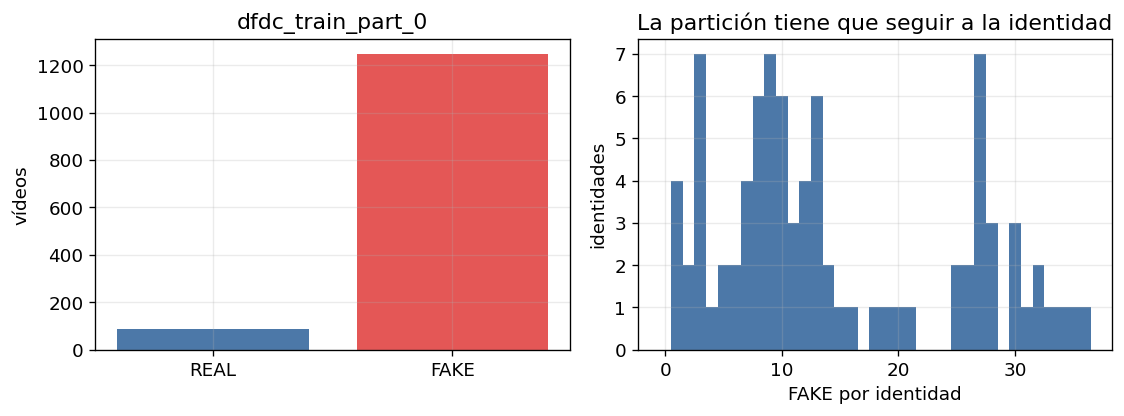

In [ ]:
metadata = json.loads((DATA_DIR / "metadata.json").read_text(encoding="utf-8"))
frame_table = pd.read_csv(MANIFEST_PATH)
if not frame_table["path"].map(lambda p: Path(p).exists()).all():
    raise FileNotFoundError("Faltan recortes del manifiesto. Hay que volver a extraer las caras.")

videos = (
    frame_table.groupby("video", sort=True)
    .agg(label=("label", "first"), y=("y", "first"), identity=("identity", "first"), frames=("frame_idx", "size"), faces=("has_face", "mean"))
    .reset_index()
)
n_real = int((videos["label"] == "REAL").sum())
n_fake = int((videos["label"] == "FAKE").sum())
original_outside = 0
for name, info in metadata.items():
    if info.get("label") != "FAKE":
        continue
    original = info.get("original")
    if original not in metadata or metadata[original].get("label") != "REAL":
        original_outside += 1

fake_counts = videos.loc[videos["label"] == "FAKE"].groupby("identity").size()
real_ids = videos.loc[videos["label"] == "REAL", "identity"]
counts = fake_counts.reindex(real_ids).fillna(0).to_numpy()
print(f"vídeos {len(videos)} | REAL {n_real} | FAKE {n_fake} | fracción FAKE {n_fake / len(videos):.3f}")
print(f"FAKE cuyo original no es un REAL de esta carpeta: {original_outside}")
print(f"FAKE por identidad: min {counts.min():.0f} | mediana {np.median(counts):.0f} | max {counts.max():.0f}")
print(f"frames {len(frame_table)} | fracción con cara {frame_table['has_face'].mean():.3f}")
print(f"accuracy de decir siempre FAKE, a nivel de vídeo: {n_fake / len(videos):.3f}")

identities = sorted(videos["identity"].unique())
median_fakes = float(np.median([int((videos["identity"] == identity).sum() - 1) for identity in identities]))
# Cada identidad aporta 1 REAL; el resto de sus vídeos son FAKE.
stratum = []
for identity in identities:
    n_fake_id = int(((videos["identity"] == identity) & (videos["label"] == "FAKE")).sum())
    stratum.append(1 if n_fake_id >= median_fakes else 0)
train_ids, hold_ids = split_ids(identities, stratum, 0.3, SEED)
hold_stratum = [1 if int(((videos["identity"] == identity) & (videos["label"] == "FAKE")).sum()) >= median_fakes else 0 for identity in hold_ids]
val_ids, test_ids = split_ids(hold_ids, hold_stratum, 2 / 3, SEED)
split_of_identity = {identity: "train" for identity in train_ids}
split_of_identity.update({identity: "val" for identity in val_ids})
split_of_identity.update({identity: "test" for identity in test_ids})
assert set(train_ids).isdisjoint(val_ids) and set(train_ids).isdisjoint(test_ids) and set(val_ids).isdisjoint(test_ids)

frame_table = frame_table.copy()
frame_table["split"] = frame_table["identity"].map(split_of_identity)
videos["split"] = videos["identity"].map(split_of_identity)

print(f"corte de estratificación (FAKE por identidad): {median_fakes:.0f}")
for split_name in ("train", "val", "test"):
    subset = videos[videos["split"] == split_name]
    print(
        f"{split_name}: vídeos {len(subset)} | REAL {(subset['label'] == 'REAL').sum()} | "
        f"FAKE {(subset['label'] == 'FAKE').sum()} | identidades {subset['identity'].nunique()}"
    )

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6))
axes[0].bar(["REAL", "FAKE"], [n_real, n_fake], color=["#4C78A8", "#E45756"])
axes[0].set_ylabel("vídeos")
axes[0].set_title("dfdc_train_part_0")
axes[1].hist(counts, bins=range(0, int(counts.max()) + 2), color="#4C78A8", align="left")
axes[1].set_xlabel("FAKE por identidad")
axes[1].set_ylabel("identidades")
axes[1].set_title("La partición tiene que seguir a la identidad")
fig.tight_layout()
fig.savefig(FIG_DIR / "comp_01_inventario.png", bbox_inches="tight")
plt.show()


## 5. Teardown

`FlopCounterMode` cuenta una multiplicación y una suma como dos operaciones. Abajo se publican multiply-adds (MACs), la mitad de esa cifra, que es la unidad del paper de EfficientNet (unos 0,39 mil millones para B0).

El campo receptivo convolucional empieza en r = 1, salto j = 1. Cada conv hace r ← r + ((k − 1) · dilatación) · j y j ← j · stride. En el ViT el cómputo local termina en el embedding de parche (kernel 14, stride 14). Desde el primer bloque de atención, el token CLS puede mirar todos los parches: el alcance pasa a ser la imagen entera. Eso es lo que la Tabla 3 del informe pedía confirmar.


In [ ]:
IMAGENET_WEIGHTS = EfficientNet_B0_Weights.IMAGENET1K_V1
PREPROCESS = IMAGENET_WEIGHTS.transforms()
IMAGENET_MEAN = tuple(PREPROCESS.mean)
IMAGENET_STD = tuple(PREPROCESS.std)
DINO_PROCESSOR = AutoImageProcessor.from_pretrained("facebook/dinov2-small")
DINO_MEAN = tuple(DINO_PROCESSOR.image_mean)
DINO_STD = tuple(DINO_PROCESSOR.image_std)
print("B0 norm", IMAGENET_MEAN, IMAGENET_STD)
print("DINOv2 norm", DINO_MEAN, DINO_STD, "| tamaño publicado", DINO_PROCESSOR.size)
print("ficha B0", IMAGENET_WEIGHTS.meta["num_params"], "params;", IMAGENET_WEIGHTS.meta["_ops"], "miles de millones de ops")


def build_b0(num_classes: int = 2) -> nn.Module:
    model = efficientnet_b0(weights=IMAGENET_WEIGHTS)
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(in_features, num_classes)
    return model


def advance_rf(rf, jump, conv):
    kernel_eff = (conv.kernel_size[0] - 1) * conv.dilation[0] + 1
    rf = rf + (kernel_eff - 1) * jump
    jump = jump * conv.stride[0]
    return rf, jump


def macs_of(module, tensor):
    counter = FlopCounterMode(display=False)
    with counter:
        output = module(tensor)
    return counter.get_total_flops() // 2, output


set_seed(SEED)
model_b0 = build_b0(2).eval()
stage_names = [
    "0 stem conv3 s2",
    "1 MBConv1 k3 ×1",
    "2 MBConv6 k3 s2 ×2",
    "3 MBConv6 k5 s2 ×2",
    "4 MBConv6 k3 s2 ×3",
    "5 MBConv6 k5 ×3",
    "6 MBConv6 k5 s2 ×4",
    "7 MBConv6 k3 ×1",
    "8 head conv1×1",
]
b0_rows = []
rf, jump = 1, 1
probe = torch.zeros(1, 3, 224, 224)
with torch.no_grad():
    for index, stage in enumerate(model_b0.features):
        params = sum(p.numel() for p in stage.parameters())
        macs, probe = macs_of(stage, probe)
        for layer in stage.modules():
            if isinstance(layer, nn.Conv2d):
                rf, jump = advance_rf(rf, jump, layer)
        b0_rows.append({"etapa": stage_names[index], "salida": list(probe.shape), "params": params, "macs": macs, "rf": rf, "se": sum(isinstance(m, SqueezeExcitation) for m in stage.modules())})
head_params = sum(p.numel() for p in model_b0.classifier.parameters())
with torch.no_grad():
    head_macs, _ = macs_of(nn.Sequential(model_b0.avgpool, nn.Flatten(1), model_b0.classifier), probe)
b0_params = sum(p.numel() for p in model_b0.parameters())
b0_macs = sum(row["macs"] for row in b0_rows) + head_macs
print(f"B0 con cabeza de 2 clases: {b0_params:,} parámetros | {b0_macs / 1e9:.4f} mil millones de MACs")
print(f"RF del último mapa: {rf} px | salto {jump} | RF del logit tras el average pool: {rf + (probe.shape[-2] - 1) * jump} px")
print(f"MBConv con atajo aditivo: {sum(getattr(m, 'use_res_connect', False) for m in model_b0.modules())}")
print("stochastic depth:", ", ".join(f"{m.p:.3f}" for m in model_b0.modules() if isinstance(m, StochasticDepth)))


B0 norm (0.485, 0.456, 0.406) (0.229, 0.224, 0.225)
DINOv2 norm (0.485, 0.456, 0.406) (0.229, 0.224, 0.225) | tamaño publicado SizeDict(height=None, width=None, longest_edge=None, shortest_edge=256, max_height=None, max_width=None, min_pixels=None, max_pixels=None)
ficha B0 5288548 params; 0.386 miles de millones de ops


B0 con cabeza de 2 clases: 4,010,110 parámetros | 0.3845 mil millones de MACs
RF del último mapa: 851 px | salto 32 | RF del logit tras el average pool: 1043 px
MBConv con atajo aditivo: 9
stochastic depth: 0.000, 0.013, 0.025, 0.038, 0.050, 0.062, 0.075, 0.088, 0.100, 0.113, 0.125, 0.138, 0.150, 0.163, 0.175, 0.188


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 223/223 [00:00<00:00, 4072.10it/s]

ViT-S/14 | capas 12 | dim 384 | cabezas 6 | MLP ×4 | SwiGLU False
tokens a 224 px: 257 (1 CLS + 16² parches)
El checkpoint fija image_size = 518 . A 224 la posición se interpola.
DINOv2: 22,056,576 parámetros | 5.5149 mil millones de MACs a 224
LayerNorm final: 768 parámetros (no suma MACs relevantes)
MACs analíticos de un bloque: 505,479,936 | medidos en el bloque 1: 454,754,304


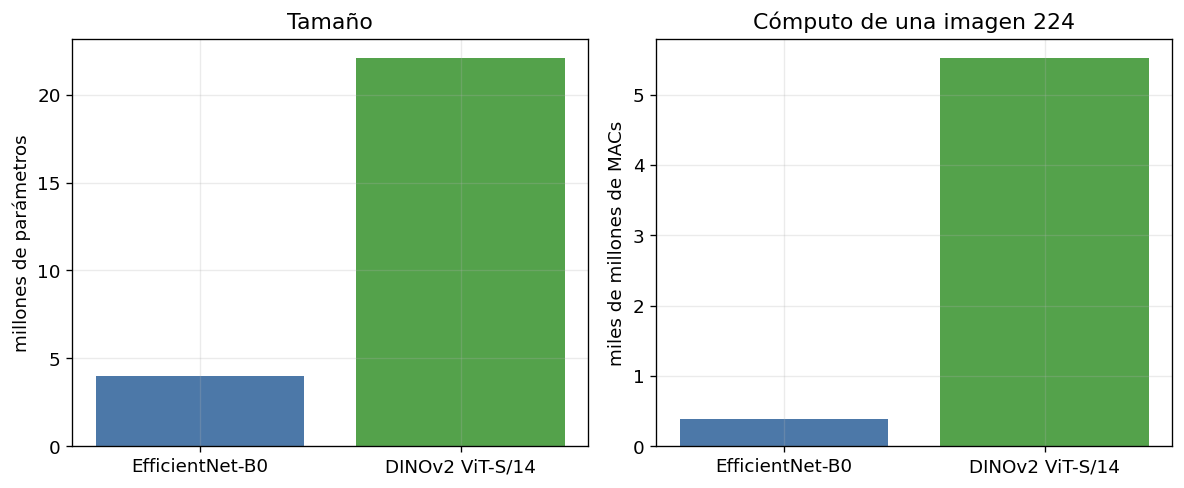

3647

In [ ]:
dino = AutoModel.from_pretrained("facebook/dinov2-small").eval()
dino_cfg = dino.config
n_tokens = 1 + (224 // dino_cfg.patch_size) ** 2
print(
    f"ViT-S/14 | capas {dino_cfg.num_hidden_layers} | dim {dino_cfg.hidden_size} | "
    f"cabezas {dino_cfg.num_attention_heads} | MLP ×{dino_cfg.mlp_ratio} | SwiGLU {dino_cfg.use_swiglu_ffn}"
)
print(f"tokens a 224 px: {n_tokens} (1 CLS + {(224 // dino_cfg.patch_size)}² parches)")
print("El checkpoint fija image_size =", dino_cfg.image_size, ". A 224 la posición se interpola.")

hidden = None
dino_rows = []
with torch.no_grad():
    macs, hidden = macs_of(dino.embeddings, torch.zeros(1, 3, 224, 224))
dino_rows.append({"bloque": "patch embed + CLS + pos", "params": sum(p.numel() for p in dino.embeddings.parameters()), "macs": macs, "alcance": "14 px"})
for index, block in enumerate(dino.encoder.layer, start=1):
    macs, hidden = macs_of(block, hidden)
    dino_rows.append(
        {
            "bloque": f"transformer {index}",
            "params": sum(p.numel() for p in block.parameters()),
            "macs": macs,
            "alcance": "imagen entera",
        }
    )
ln_params = sum(p.numel() for p in dino.layernorm.parameters())
dino_params = sum(p.numel() for p in dino.parameters())
dino_macs = sum(row["macs"] for row in dino_rows)
print(f"DINOv2: {dino_params:,} parámetros | {dino_macs / 1e9:.4f} mil millones de MACs a 224")
print(f"LayerNorm final: {ln_params:,} parámetros (no suma MACs relevantes)")
assert dino_params == sum(row["params"] for row in dino_rows) + ln_params

# Fórmula del bloque, para defender el contador.
# Q,K,V y proyección: 4 N C^2. Atención: 2 N^2 C. MLP ratio 4: 8 N C^2.
n, c = n_tokens, dino_cfg.hidden_size
analytic = 12 * n * c * c + 2 * n * n * c
measured = dino_rows[1]["macs"]
print(f"MACs analíticos de un bloque: {analytic:,} | medidos en el bloque 1: {measured:,}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
axes[0].bar(["EfficientNet-B0", "DINOv2 ViT-S/14"], [b0_params / 1e6, dino_params / 1e6], color=["#4C78A8", "#54A24B"])
axes[0].set_ylabel("millones de parámetros")
axes[0].set_title("Tamaño")
axes[1].bar(["EfficientNet-B0", "DINOv2 ViT-S/14"], [b0_macs / 1e9, dino_macs / 1e9], color=["#4C78A8", "#54A24B"])
axes[1].set_ylabel("miles de millones de MACs")
axes[1].set_title("Cómputo de una imagen 224")
fig.tight_layout()
fig.savefig(FIG_DIR / "comp_02_costo.png", bbox_inches="tight")
plt.show()

(OUT_DIR / "teardown.json").write_text(
    json.dumps({"b0_params": b0_params, "b0_macs": b0_macs, "dino_params": dino_params, "dino_macs": dino_macs, "b0": b0_rows, "dino": dino_rows}, indent=2),
    encoding="utf-8",
)


In [ ]:
def measure_latency(net, batch, forward):
    net = net.to(DEVICE).eval()
    sample = torch.randn(batch, 3, 224, 224, device=DEVICE)
    torch.cuda.reset_peak_memory_stats()
    with torch.no_grad():
        for _ in range(10):
            forward(net, sample)
        torch.cuda.synchronize()
        start, end = torch.cuda.Event(True), torch.cuda.Event(True)
        start.record()
        steps = 30
        for _ in range(steps):
            forward(net, sample)
        end.record()
        torch.cuda.synchronize()
    milliseconds = start.elapsed_time(end) / steps
    return {
        "batch": batch,
        "ms": round(milliseconds, 2),
        "imagenes_por_s": round(1000 * batch / milliseconds, 1),
        "memoria_MB": round(torch.cuda.max_memory_allocated() / (1024 ** 2), 1),
    }


def forward_b0(net, sample):
    return net(sample)


def forward_dino(net, sample):
    return net(pixel_values=sample).pooler_output


if DEVICE.type != "cuda":
    print("Sin CUDA no se mide latencia.")
else:
    for name, net, forward in (("B0", model_b0, forward_b0), ("DINOv2", dino, forward_dino)):
        for batch in (1, 16):
            row = measure_latency(net, batch, forward)
            print(name, row)


B0 {'batch': 1, 'ms': 9.43, 'imagenes_por_s': 106.0, 'memoria_MB': 34.2}


B0 {'batch': 16, 'ms': 13.21, 'imagenes_por_s': 1211.4, 'memoria_MB': 193.1}


DINOv2 {'batch': 1, 'ms': 7.99, 'imagenes_por_s': 125.2, 'memoria_MB': 113.5}


DINOv2 {'batch': 16, 'ms': 41.45, 'imagenes_por_s': 386.0, 'memoria_MB': 189.7}


## 6. Intervención preliminar

P-1, P-2 y P-3 están declaradas en la sección 3, con la regla del intervalo, antes de esta corrida. El conjunto de prueba no entra al entrenamiento ni elige la época. La época de B0 es la quinta. DINOv2 no recibe gradiente: solo se ajustan la media, la escala y la regresión logística sobre el CLS.

Las degradaciones se aplican al recorte ya guardado, sin reentrenar. JPEG calidad 30 recomprime el PNG/JPEG de 224. La mitad de resolución baja el recorte a 112 y lo devuelve a 224, que es la entrada que los dos modelos saben leer.


In [ ]:
class FaceFrames(Dataset):
    def __init__(self, rows, train=False, degradation="clean", mean=None, std=None):
        self.rows = rows.reset_index(drop=True)
        self.train = train
        self.degradation = degradation
        self.mean = IMAGENET_MEAN if mean is None else mean
        self.std = IMAGENET_STD if std is None else std

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows.iloc[index]
        image = Image.open(row["path"]).convert("RGB")
        if self.degradation == "jpeg30":
            buffer = io.BytesIO()
            image.save(buffer, format="JPEG", quality=30)
            buffer.seek(0)
            image = Image.open(buffer).convert("RGB")
        elif self.degradation == "half":
            image = image.resize((112, 112), Image.Resampling.BILINEAR).resize((224, 224), Image.Resampling.BILINEAR)
        if self.train and random.random() < 0.5:
            image = TF.hflip(image)
        tensor = TF.normalize(TF.to_tensor(image), self.mean, self.std)
        return tensor, int(row["y"]), row["video"]


def make_loader(rows, train=False, degradation="clean", mean=None, std=None):
    generator = torch.Generator()
    generator.manual_seed(SEED)
    return DataLoader(
        FaceFrames(rows, train=train, degradation=degradation, mean=mean, std=std),
        batch_size=BATCH_SIZE,
        shuffle=train,
        drop_last=train,
        num_workers=0,
        pin_memory=DEVICE.type == "cuda",
        generator=generator if train else None,
    )


def aggregate(videos, probs, targets):
    bucket, target_of = defaultdict(list), {}
    for video, prob, target in zip(videos, probs, targets):
        bucket[video].append(float(prob))
        target_of[video] = int(target)
    order = sorted(bucket)
    scores = np.array([float(np.mean(bucket[video])) for video in order])
    labels = np.array([target_of[video] for video in order])
    return scores, labels, order


def class_weights(rows):
    y = rows["y"].to_numpy()
    total = len(y)
    return torch.tensor([total / (2 * max(int((y == cls).sum()), 1)) for cls in (0, 1)], dtype=torch.float32, device=DEVICE)


train_rows = frame_table[frame_table["split"] == "train"]
val_rows = frame_table[frame_table["split"] == "val"]
test_rows = frame_table[frame_table["split"] == "test"]
print("frames", len(train_rows), len(val_rows), len(test_rows))
print("pesos CE [REAL, FAKE]", [round(v, 3) for v in class_weights(train_rows).tolist()])


def fit_b0():
    set_seed(SEED)
    net = build_b0(2).to(DEVICE)
    criterion = nn.CrossEntropyLoss(weight=class_weights(train_rows))
    optimizer = torch.optim.AdamW((p for p in net.parameters() if p.requires_grad), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    train_loader = make_loader(train_rows, train=True)
    val_loader = make_loader(val_rows, train=False)
    history = []
    for epoch in range(1, EPOCHS + 1):
        net.train()
        running, seen = 0.0, 0
        for batch_x, batch_y, _video in train_loader:
            batch_x = batch_x.to(DEVICE, non_blocking=True)
            batch_y = batch_y.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(net(batch_x), batch_y)
            if not torch.isfinite(loss):
                raise RuntimeError(f"Pérdida no finita en la época {epoch}.")
            loss.backward()
            optimizer.step()
            running += loss.item() * batch_x.size(0)
            seen += batch_x.size(0)
        scheduler.step()
        scores, labels, _order = predict_b0(net, val_loader)
        record = {"epoch": epoch, "train_loss": running / max(seen, 1), "val_auc": float(roc_auc_score(labels, scores))}
        history.append(record)
        print(f"B0 época {epoch} | loss {record['train_loss']:.4f} | AUC val {record['val_auc']:.4f}")
    torch.save(net.state_dict(), OUT_DIR / "b0_epoca5.pt")
    return net, history


def predict_b0(net, loader):
    net.eval()
    probs, targets, videos = [], [], []
    with torch.no_grad():
        for batch_x, batch_y, batch_video in loader:
            prob = torch.softmax(net(batch_x.to(DEVICE)), dim=1)[:, 1]
            probs.append(prob.cpu().numpy())
            targets.append(np.asarray(batch_y))
            videos.extend(list(batch_video))
    return aggregate(videos, np.concatenate(probs), np.concatenate(targets))


print("P-1, P-2 y P-3 se leen al final, en el conjunto de prueba, no en esta curva de validación.")
model_b0, b0_history = fit_b0()
b0_test_scores, b0_test_y, b0_test_videos = predict_b0(model_b0, make_loader(test_rows))
print(f"B0 época 5 | AUC test {roc_auc_score(b0_test_y, b0_test_scores):.4f}")


frames 7360 824 2488
pesos CE [REAL, FAKE] [7.667, 0.535]
P-1, P-2 y P-3 se leen al final, en el conjunto de prueba, no en esta curva de validación.


B0 época 1 | loss 0.4576 | AUC val 0.9947


B0 época 2 | loss 0.2289 | AUC val 0.9974


B0 época 3 | loss 0.1361 | AUC val 0.9974


B0 época 4 | loss 0.1027 | AUC val 0.9987


B0 época 5 | loss 0.0865 | AUC val 1.0000


B0 época 5 | AUC test 0.9970


In [ ]:
@torch.no_grad()
def extract_cls(rows, degradation="clean"):
    dino.to(DEVICE).eval()
    loader = make_loader(rows, train=False, degradation=degradation, mean=DINO_MEAN, std=DINO_STD)
    finals, blocks, videos, targets = [], [], [], []
    for batch_x, batch_y, batch_video in loader:
        output = dino(pixel_values=batch_x.to(DEVICE), output_hidden_states=True)
        # hidden_states[0] es el embedding; [1]..[12] son los bloques.
        stacked = torch.stack([state[:, 0] for state in output.hidden_states[1:]], dim=1)
        finals.append(output.pooler_output.float().cpu().numpy())
        blocks.append(stacked.float().cpu().numpy())
        videos.extend(list(batch_video))
        targets.extend(int(v) for v in batch_y)
    return {
        "video": videos,
        "y": np.asarray(targets),
        "final": np.concatenate(finals),
        "blocks": np.concatenate(blocks),
    }


def fit_probe(features, labels):
    scaler = StandardScaler()
    train_x = scaler.fit_transform(features)
    probe = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)
    probe.fit(train_x, labels)
    return scaler, probe


def probe_video_scores(scaler, probe, features, labels, videos):
    prob = probe.predict_proba(scaler.transform(features))[:, 1]
    return aggregate(videos, prob, labels)


print("Extrayendo CLS limpio de DINOv2 (congelado)...")
clean = {
    "train": extract_cls(train_rows),
    "val": extract_cls(val_rows),
    "test": extract_cls(test_rows),
}
scaler, probe = fit_probe(clean["train"]["final"], clean["train"]["y"])
dino_test_scores, dino_test_y, dino_test_videos = probe_video_scores(
    scaler, probe, clean["test"]["final"], clean["test"]["y"], clean["test"]["video"]
)
assert dino_test_videos == b0_test_videos
assert np.array_equal(dino_test_y, b0_test_y)
print(f"DINOv2 probe | AUC test {roc_auc_score(dino_test_y, dino_test_scores):.4f} | iteraciones {probe.n_iter_[0]}")

block_aucs = []
for block_index in range(12):
    block_scaler, block_probe = fit_probe(clean["train"]["blocks"][:, block_index], clean["train"]["y"])
    scores, labels, _videos = probe_video_scores(
        block_scaler, block_probe, clean["test"]["blocks"][:, block_index], clean["test"]["y"], clean["test"]["video"]
    )
    block_aucs.append(float(roc_auc_score(labels, scores)))
    print(f"bloque {block_index + 1:02d} | AUC test {block_aucs[-1]:.4f}")
best_block = int(np.argmax(block_aucs)) + 1
print(f"máximo en el bloque {best_block} de 12")


Extrayendo CLS limpio de DINOv2 (congelado)...


DINOv2 probe | AUC test 0.9888 | iteraciones 250


bloque 01 | AUC test 0.8675


bloque 02 | AUC test 0.8925


bloque 03 | AUC test 0.9378


...

bloque 08 | AUC test 0.9664


bloque 09 | AUC test 0.9816


bloque 10 | AUC test 0.9856


bloque 11 | AUC test 0.9928


bloque 12 | AUC test 0.9882
máximo en el bloque 11 de 12


In [ ]:
print("Degradaciones solo en prueba, sin reentrenar.")
stress = {}
for name in ("jpeg30", "half"):
    degraded = extract_cls(test_rows, degradation=name)
    dino_scores, labels, videos = probe_video_scores(scaler, probe, degraded["final"], degraded["y"], degraded["video"])
    b0_scores, b0_labels, b0_videos = predict_b0(model_b0, make_loader(test_rows, degradation=name))
    assert videos == b0_videos == b0_test_videos
    stress[name] = {"y": labels, "b0": b0_scores, "dino": dino_scores}
    print(
        f"{name} | AUC B0 {roc_auc_score(labels, b0_scores):.4f} | "
        f"AUC DINOv2 {roc_auc_score(labels, dino_scores):.4f}"
    )


Degradaciones solo en prueba, sin reentrenar.


jpeg30 | AUC B0 0.9397 | AUC DINOv2 0.9374


half | AUC B0 0.9217 | AUC DINOv2 0.9672


PRUEBA, época 5 / probe lineal
b0 {'auc': 0.997, 'logloss': 0.079, 'eer': 0.0085, 'balanced_acc_0.5': 0.9637}
dino {'auc': 0.9888, 'logloss': 0.2132, 'eer': 0.0568, 'balanced_acc_0.5': 0.9223}
ΔAUC B0 − DINOv2 percentiles 5, 50, 95: 0.0016, 0.0079, 0.0169
P-1: compatible con P-1: el intervalo de AUC(B0) − AUC(DINOv2) queda por encima de 0.
jpeg30 | AUC B0 0.9397 | AUC DINOv2 0.9374 | Δcaída percentiles -0.0512, -0.0063, 0.0389
P-2: no concluyente: el intervalo contiene 0.
half | AUC B0 0.9217 | AUC DINOv2 0.9672 | Δcaída percentiles -0.1109, -0.0504, -0.0022
P-2: compatible con P-2: la caída de DINOv2 es menor y el intervalo queda por debajo de 0.
P-3: compatible con P-3 en esta partición: el máximo está en el bloque 11, no en el 12.
accuracy del constante FAKE en prueba: 0.942. No es la métrica de las hipótesis.


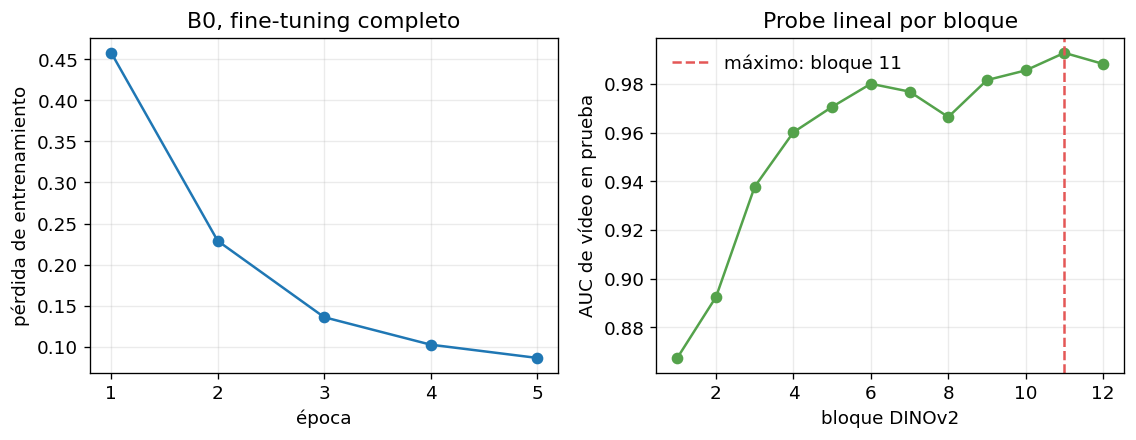

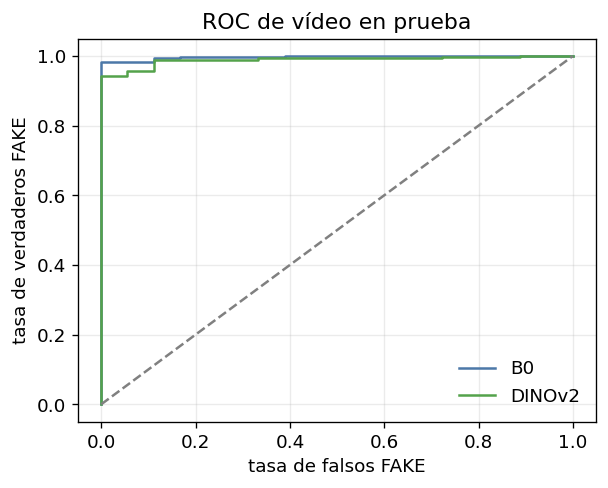

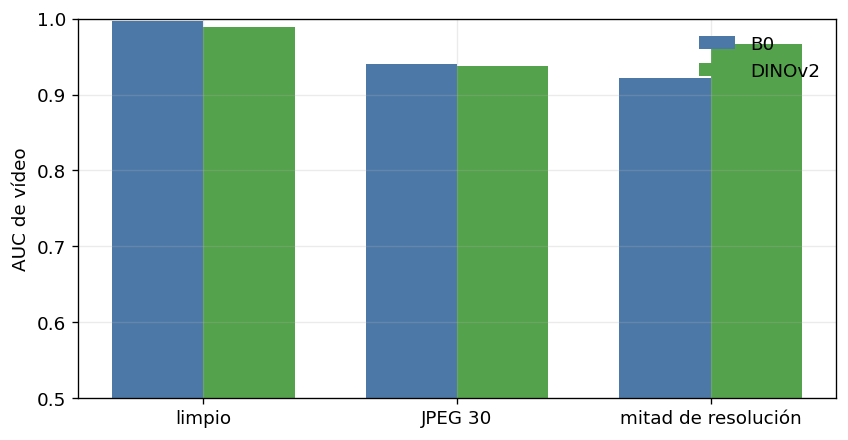

2314

In [ ]:
def equal_error_rate(labels, scores):
    fpr, tpr, _thresholds = roc_curve(labels, scores)
    fnr = 1 - tpr
    index = int(np.argmin(np.abs(fpr - fnr)))
    return float((fpr[index] + fnr[index]) / 2)


def video_metrics(labels, scores):
    clipped = np.clip(scores, 1e-6, 1 - 1e-6)
    return {
        "auc": float(roc_auc_score(labels, scores)),
        "logloss": float(log_loss(labels, clipped, labels=[0, 1])),
        "eer": equal_error_rate(labels, scores),
        "balanced_acc_0.5": float(balanced_accuracy_score(labels, (scores >= 0.5).astype(int))),
    }


def bootstrap_diff(labels, score_a, score_b, statistic):
    rng = np.random.default_rng(SEED)
    diffs = []
    n = len(labels)
    for _ in range(BOOTSTRAP_DRAWS):
        index = rng.integers(0, n, n)
        if len(np.unique(labels[index])) < 2:
            continue
        diffs.append(statistic(labels[index], score_a[index], score_b[index]))
    diffs = np.asarray(diffs)
    low, mid, high = np.quantile(diffs, [0.05, 0.5, 0.95])
    return {"p05": float(low), "p50": float(mid), "p95": float(high), "n": int(diffs.size)}


def interval_reading(interval, positive_means, negative_means):
    if interval["p05"] > 0:
        return positive_means
    if interval["p95"] < 0:
        return negative_means
    return "no concluyente: el intervalo contiene 0."


labels = b0_test_y
metrics = {"b0": video_metrics(labels, b0_test_scores), "dino": video_metrics(labels, dino_test_scores)}
delta_auc = bootstrap_diff(labels, b0_test_scores, dino_test_scores, lambda y, a, b: roc_auc_score(y, a) - roc_auc_score(y, b))
p1 = interval_reading(
    delta_auc,
    "compatible con P-1: el intervalo de AUC(B0) − AUC(DINOv2) queda por encima de 0.",
    "P-1 refutada en esta partición: el intervalo queda por debajo de 0.",
)

stress_reading = {}
for name, payload in stress.items():
    rng = np.random.default_rng(SEED)
    diffs = []
    y_clean = labels
    for _ in range(BOOTSTRAP_DRAWS):
        index = rng.integers(0, len(y_clean), len(y_clean))
        if len(np.unique(y_clean[index])) < 2:
            continue
        drop_dino = roc_auc_score(y_clean[index], dino_test_scores[index]) - roc_auc_score(y_clean[index], payload["dino"][index])
        drop_b0 = roc_auc_score(y_clean[index], b0_test_scores[index]) - roc_auc_score(y_clean[index], payload["b0"][index])
        diffs.append(drop_dino - drop_b0)
    diffs = np.asarray(diffs)
    drop = {"p05": float(np.quantile(diffs, 0.05)), "p50": float(np.quantile(diffs, 0.5)), "p95": float(np.quantile(diffs, 0.95))}
    stress_reading[name] = {
        "drop_interval": drop,
        "auc_b0": float(roc_auc_score(labels, payload["b0"])),
        "auc_dino": float(roc_auc_score(labels, payload["dino"])),
        "lectura": interval_reading(
            drop,
            "P-2 refutada en esta degradación: DINOv2 cae tanto o más que B0 y el intervalo queda por encima de 0.",
            "compatible con P-2: la caída de DINOv2 es menor y el intervalo queda por debajo de 0.",
        ),
    }

p3 = (
    f"P-3 refutada en esta partición: el máximo está en el bloque {best_block}, que es el último."
    if best_block == 12
    else f"compatible con P-3 en esta partición: el máximo está en el bloque {best_block}, no en el 12."
)

print("PRUEBA, época 5 / probe lineal")
for name, row in metrics.items():
    print(name, {key: round(value, 4) for key, value in row.items()})
print(f"ΔAUC B0 − DINOv2 percentiles 5, 50, 95: {delta_auc['p05']:.4f}, {delta_auc['p50']:.4f}, {delta_auc['p95']:.4f}")
print("P-1:", p1)
for name, row in stress_reading.items():
    interval = row["drop_interval"]
    print(
        f"{name} | AUC B0 {row['auc_b0']:.4f} | AUC DINOv2 {row['auc_dino']:.4f} | "
        f"Δcaída percentiles {interval['p05']:.4f}, {interval['p50']:.4f}, {interval['p95']:.4f}"
    )
    print("P-2:", row["lectura"])
print("P-3:", p3)
print(f"accuracy del constante FAKE en prueba: {labels.mean():.3f}. No es la métrica de las hipótesis.")

fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.8))
epochs = [row["epoch"] for row in b0_history]
axes[0].plot(epochs, [row["train_loss"] for row in b0_history], marker="o")
axes[0].set_xlabel("época")
axes[0].set_ylabel("pérdida de entrenamiento")
axes[0].set_title("B0, fine-tuning completo")
axes[1].plot(range(1, 13), block_aucs, marker="o", color="#54A24B")
axes[1].axvline(best_block, color="#E45756", ls="--", label=f"máximo: bloque {best_block}")
axes[1].set_xlabel("bloque DINOv2")
axes[1].set_ylabel("AUC de vídeo en prueba")
axes[1].set_title("Probe lineal por bloque")
axes[1].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "comp_03_curvas.png", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(5.2, 4.2))
for scores, name, color in ((b0_test_scores, "B0", "#4C78A8"), (dino_test_scores, "DINOv2", "#54A24B")):
    fpr, tpr, _ = roc_curve(labels, scores)
    ax.plot(fpr, tpr, color=color, label=name)
ax.plot([0, 1], [0, 1], ls="--", color="gray")
ax.set_xlabel("tasa de falsos FAKE")
ax.set_ylabel("tasa de verdaderos FAKE")
ax.set_title("ROC de vídeo en prueba")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "comp_04_roc.png", bbox_inches="tight")
plt.show()

conditions = ["limpio", "JPEG 30", "mitad de resolución"]
b0_bars = [metrics["b0"]["auc"], stress_reading["jpeg30"]["auc_b0"], stress_reading["half"]["auc_b0"]]
dino_bars = [metrics["dino"]["auc"], stress_reading["jpeg30"]["auc_dino"], stress_reading["half"]["auc_dino"]]
xpos = np.arange(len(conditions))
fig, ax = plt.subplots(figsize=(7.2, 3.8))
ax.bar(xpos - 0.18, b0_bars, width=0.36, label="B0", color="#4C78A8")
ax.bar(xpos + 0.18, dino_bars, width=0.36, label="DINOv2", color="#54A24B")
ax.set_xticks(xpos)
ax.set_xticklabels(conditions)
ax.set_ylim(0.5, 1.0)
ax.set_ylabel("AUC de vídeo")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "comp_05_degradaciones.png", bbox_inches="tight")
plt.show()

summary = {
    "metricas_test": metrics,
    "delta_auc_b0_minus_dino": delta_auc,
    "lectura_p1": p1,
    "estres": stress_reading,
    "auc_por_bloque": block_aucs,
    "bloque_maximo": best_block,
    "lectura_p3": p3,
    "historia_b0": b0_history,
    "n_videos_test": int(len(labels)),
}
(OUT_DIR / "lectura_preliminar.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")


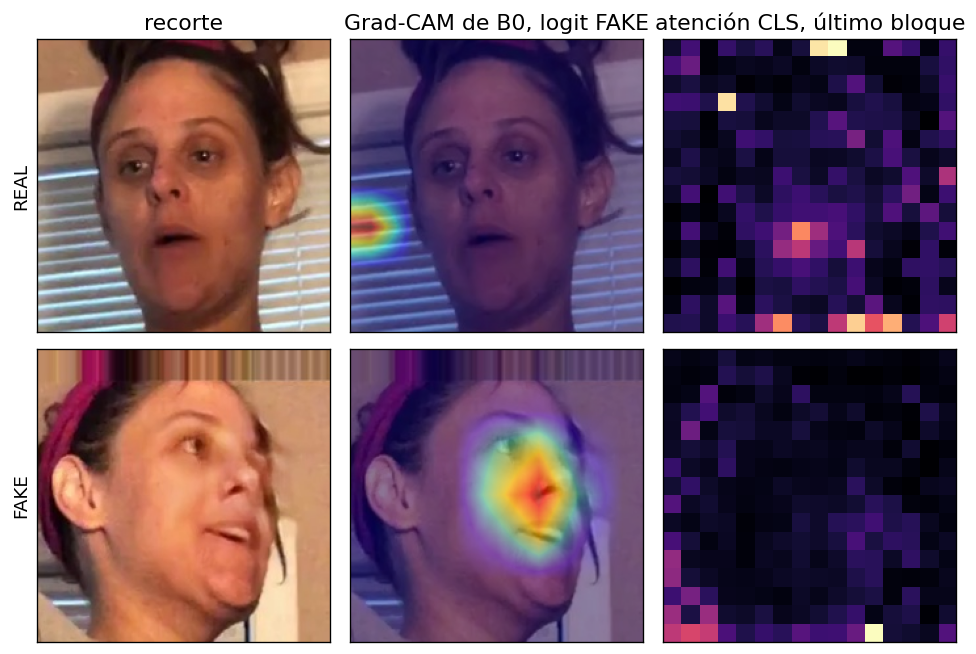

In [ ]:
def first_test_row(label_name):
    subset = test_rows[(test_rows["label"] == label_name) & (test_rows["has_face"] == 1)]
    return subset.iloc[0]


def show_gradcam(net, row):
    image = Image.open(row["path"]).convert("RGB")
    tensor = TF.normalize(TF.to_tensor(image), IMAGENET_MEAN, IMAGENET_STD).unsqueeze(0).to(DEVICE)
    feats = {}

    def hook(_module, _inputs, output):
        output.retain_grad()
        feats["map"] = output

    handle = net.features[-1].register_forward_hook(hook)
    net.eval()
    net.zero_grad(set_to_none=True)
    logit = net(tensor)[0, 1]
    logit.backward()
    handle.remove()
    weights = feats["map"].grad.mean(dim=(2, 3), keepdim=True)
    heat = torch.relu((weights * feats["map"]).sum(dim=1))[0]
    heat = heat - heat.min()
    heat = heat / heat.max().clamp_min(1e-8)
    heat = TF.resize(heat.detach().cpu().unsqueeze(0), [224, 224], antialias=False)[0].numpy()
    return np.asarray(image), heat


def cls_attention(net, row):
    image = Image.open(row["path"]).convert("RGB")
    tensor = TF.normalize(TF.to_tensor(image), DINO_MEAN, DINO_STD).unsqueeze(0).to(DEVICE)
    captured = {}

    def hook(_module, inputs, _output):
        captured["x"] = inputs[0].detach()

    handle = net.encoder.layer[-1].attention.register_forward_hook(hook)
    net.eval()
    with torch.no_grad():
        net(pixel_values=tensor)
    handle.remove()
    tokens = captured["x"]
    attn = net.encoder.layer[-1].attention
    heads = attn.num_attention_heads
    head_dim = attn.head_dim
    query = attn.q_proj(tokens).view(1, -1, heads, head_dim).transpose(1, 2)
    key = attn.k_proj(tokens).view(1, -1, heads, head_dim).transpose(1, 2)
    weights = torch.softmax((query * attn.scaling) @ key.transpose(-2, -1), dim=-1)
    grid = int((weights.shape[-1] - 1) ** 0.5)
    cls_map = weights[0, :, 0, 1:].mean(0).reshape(grid, grid).detach().cpu().numpy()
    return np.asarray(image), cls_map


model_b0.to(DEVICE)
dino.to(DEVICE)
fig, axes = plt.subplots(2, 3, figsize=(8.2, 5.6))
for row_index, label_name in enumerate(("REAL", "FAKE")):
    sample = first_test_row(label_name)
    rgb, heat = show_gradcam(model_b0, sample)
    _rgb, cls_map = cls_attention(dino, sample)
    axes[row_index, 0].imshow(rgb)
    axes[row_index, 0].set_ylabel(label_name)
    axes[row_index, 1].imshow(rgb)
    axes[row_index, 1].imshow(heat, cmap="jet", alpha=0.45)
    axes[row_index, 2].imshow(cls_map, cmap="magma")
    for axis in axes[row_index]:
        axis.set_xticks([])
        axis.set_yticks([])
axes[0, 0].set_title("recorte")
axes[0, 1].set_title("Grad-CAM de B0, logit FAKE")
axes[0, 2].set_title("atención CLS, último bloque")
fig.tight_layout()
fig.savefig(FIG_DIR / "comp_06_mapas.png", bbox_inches="tight")
plt.show()


## 7. Lectura y lo que sigue abierto

Los párrafos de números no van aquí: los imprime la celda anterior a partir de `resultados/e1_b0_dinov2/lectura_preliminar.json`. Lo que sí queda fijo, haya salido lo que haya salido, es el alcance.

Esta prueba tiene una semilla y un solo fragmento de DFDC. El bootstrap no crea otra semilla. Un AUC alto dentro de la partición no responde H-B: las 18 identidades de prueba, o las que hayan caído en ese lado, siguen siendo deepfakes del mismo fragmento, no otro generador ni otro dataset. El metadato no dice si el falso es de cara, de voz o de ambos, así que parte del error puede ser etiqueta visual sobre un vídeo que solo cambia el audio.

DINOv2 entra a 224 px, no a los 518 de su entrenamiento, porque la Tabla 4 iguala la entrada de los dos modelos. Si P-1 favorece a B0, una parte de esa ventaja puede ser la interpolación de la posición y no la supervisión de ImageNet. Si P-1 favorece a DINOv2 aun con esa desventaja, el resultado es más fuerte de lo que el protocolo aparenta.

Queda fuera, como en el informe: LoRA, fine-tuning de los últimos bloques, Self-Blended Images, FaceForensics++, Celeb-DF, varias semillas y el tratamiento de los falsos solo de voz.

**Ética.** DFDC exige aceptar las reglas de la competencia; los vídeos no se redistribuyen. Las caras que muestra este cuaderno son para el análisis del curso. El metadato no trae edad, sexo ni tono de piel, así que no hay un resultado de equidad. Un detector que se equivoca acusa un vídeo real o deja pasar una falsificación; por eso la métrica principal es el AUC y no un umbral suelto. Contar qué degradación tumba al detector también le sirve a quien quiera evadirlo: el informe final tiene que reportarlo con ese cuidado.

**Defensa.** Cada integrante tiene que poder explicar por qué la partición usa `original`, qué queda congelado en DINOv2, por qué el CLS no es un fine-tuning, cómo se calcula la caída de P-2 y qué parte escribieron Claude y el agente de Cursor.
